In [36]:
#imports modules
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#set root and import functions
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.utilities import build_individual_grb_table, separate_flare_data

In [37]:
#read in data
df=pd.read_csv('../data/xrt_data_from_phd.csv')

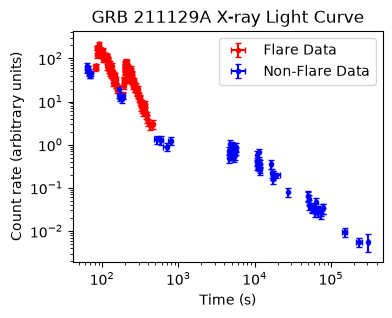

In [38]:
#load and test a light curve for a single random GRB
choice=np.random.choice(df['GRB'].unique())
data=build_individual_grb_table(df,choice)
# print(data.columns)

#separate the flare data, if any
flare_data,non_flare_data,full_data=separate_flare_data(data)

#make plot 
fig,axs=plt.subplots(figsize=(4,3))

#plot flare data
if flare_data is not None:
    axs.errorbar(flare_data["Time"], flare_data["Rate"], xerr=[np.abs(flare_data["TimeNeg"]),np.abs(flare_data["TimePos"])], yerr=[np.abs(flare_data["RateNeg"]),np.abs(flare_data["RatePos"])] ,fmt="o", markersize=3,capsize=2, color='red', label='Flare Data')

#plot non flare data
if non_flare_data is not None:
    axs.errorbar(non_flare_data["Time"], non_flare_data["Rate"], xerr=[np.abs(non_flare_data["TimeNeg"]),np.abs(non_flare_data["TimePos"])], yerr=[np.abs(non_flare_data["RateNeg"]),np.abs(non_flare_data["RatePos"])] ,fmt="o", markersize=3,capsize=2, color='blue', label='Non-Flare Data')

# #plot full LC
# axs.errorbar(full_data["Time"], full_data["Rate"], xerr=[np.abs(full_data["TimeNeg"]),np.abs(full_data["TimePos"])], yerr=[np.abs(full_data["RateNeg"]),np.abs(full_data["RatePos"])] ,fmt="o", markersize=3,capsize=2,color='blue', label='Non-flare Data')

#format and produce plot
axs.set_xscale("log")
axs.set_yscale("log")
axs.set_xlabel("Time (s)")
axs.set_ylabel("Count rate (arbitrary units)")
axs.set_title("GRB {} X-ray Light Curve".format(data["GRB"].iloc[0]))
axs.legend()
plt.show()


In [ ]:
# Compare the different versions (works whether a dataframe is None or empty)
print("Flare data:")
print(flare_data.head(4) if flare_data is not None else "None (no flares)")

print("\nNon-flare data:")
print(non_flare_data.head(4))

print("\nFull data:")
print(full_data.head(4))

# Sanity check: flare + non-flare rows should equal the full data
n_flare=0 if flare_data is None else len(flare_data)
print(f"\nflare ({n_flare}) + non-flare ({len(non_flare_data)}) = {n_flare + len(non_flare_data)}, full={len(full_data)}")

Flare data:
           GRB    Time TimePos TimeNeg      Rate   RatePos   RateNeg  \
14640  211129A  80.653   0.661   -0.88  60.15604  9.554178 -8.998281   
14641  211129A  82.124   0.585   -0.81  64.25187  10.36121 -10.04786   
14642  211129A  83.437   0.696  -0.729  65.03781    9.8283 -9.699399   
14643  211129A   84.84   0.449  -0.706  116.8601  14.98697 -14.72915   

          lctype Flare_1_start Flare_1_end  ... Flare_10_start Flare_10_end  \
14640  Canonical        79.773     162.089  ...            NaN          NaN   
14641  Canonical        79.773     162.089  ...            NaN          NaN   
14642  Canonical        79.773     162.089  ...            NaN          NaN   
14643  Canonical        79.773     162.089  ...            NaN          NaN   

      Flare_11_start Flare_11_end Flare_12_start Flare_12_end Flare_13_start  \
14640            NaN          NaN            NaN          NaN            NaN   
14641            NaN          NaN            NaN          NaN          